QN1

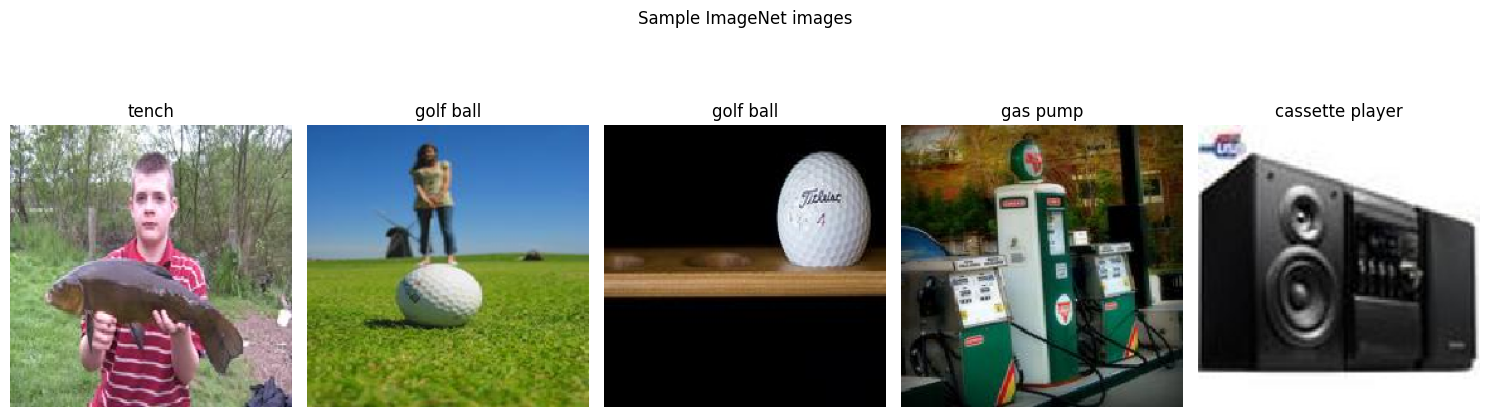

Original class labels:
- gas pump

Top-5 predicted classes:
1. gas pump
2. cash machine
3. ambulance
4. pay-phone
5. vending machine

Prediction probabilities:
1. gas pump: 97.67%
2. cash machine: 2.14%
3. ambulance: 0.08%
4. pay-phone: 0.04%
5. vending machine: 0.03%

Preprocessed image representation:
Shape: (1, 224, 224, 3)
Data type: float32
Minimum pixel value: -123.6800
Maximum pixel value: 151.0610


In [ ]:
# ============================================================
# QUESTION 1: IMAGENET IMAGE PREPROCESSING AND CNN ANALYSIS
# ============================================================

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import (
    preprocess_input,
    decode_predictions
)
from tensorflow.keras.utils import load_img, img_to_array

# ------------------------------------------------------------
# 1. ACCESS LOCAL DATASET DIRECTORY AND CLASS MAPPINGS
# ------------------------------------------------------------

DATASET_DIR = "ImageNet/dataset"
MAPPING_FILE = "ImageNet/class_mapping.json"

IMG_SIZE = (224, 224)

# Check whether the dataset directory exists
if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_DIR}"
    )

# Check whether the JSON mapping file exists
if not os.path.isfile(MAPPING_FILE):
    raise FileNotFoundError(
        f"Class mapping JSON file not found: {MAPPING_FILE}"
    )

# Load class mappings from JSON
with open(MAPPING_FILE, "r") as file:
    label_mapping = json.load(file)

np.random.seed(42)
tf.random.set_seed(42)


# ------------------------------------------------------------
# 2. COLLECT IMAGE PATHS AND CLASS LABELS
# ------------------------------------------------------------

def collect_images(directory):
    paths = []
    labels = []

    for class_folder in sorted(os.listdir(directory)):
        class_path = os.path.join(directory, class_folder)

        if not os.path.isdir(class_path):
            continue

        # Map folder ID to its readable class name
        class_name = label_mapping.get(class_folder, class_folder)

        for filename in sorted(os.listdir(class_path)):
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            ):
                image_path = os.path.join(class_path, filename)

                paths.append(image_path)
                labels.append(class_name)

    return paths, labels


X_image_paths, y_labels = collect_images(DATASET_DIR)

if len(X_image_paths) == 0:
    raise ValueError(
        f"No images found in the dataset directory: {DATASET_DIR}"
    )

print("Total images:", len(X_image_paths))
print("Total classes:", len(set(y_labels)))
print("Sample class labels:", y_labels[:5])
print()


# ------------------------------------------------------------
# 3. IMAGE PREPROCESSING
# ------------------------------------------------------------

def load_preprocess_image(path):
    image = load_img(path, target_size=IMG_SIZE)
    image = img_to_array(image)
    image = np.expand_dims(image, axis=0)
    image = preprocess_input(image)

    return image


# ------------------------------------------------------------
# OUTPUT 1: SAMPLE IMAGES WITH CLASS LABELS
# ------------------------------------------------------------

sample_indices = np.random.choice(
    len(X_image_paths),
    size=min(5, len(X_image_paths)),
    replace=False
)

plt.figure(figsize=(15, 5))

for i, index in enumerate(sample_indices):
    image = load_img(
        X_image_paths[index],
        target_size=IMG_SIZE
    )

    plt.subplot(1, len(sample_indices), i + 1)
    plt.imshow(image)
    plt.title(y_labels[index])
    plt.axis("off")

plt.suptitle("Sample ImageNet Images")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. LOAD PRETRAINED RESNET50 MODEL
# ------------------------------------------------------------

model = ResNet50(
    weights="imagenet",
    include_top=True,
    input_shape=(224, 224, 3)
)

# Select a random image for prediction
test_index = np.random.randint(len(X_image_paths))

test_path = X_image_paths[test_index]
original_label = y_labels[test_index]

processed_image = load_preprocess_image(test_path)

predictions = model.predict(processed_image, verbose=0)

top5 = decode_predictions(predictions, top=5)[0]


# ------------------------------------------------------------
# OUTPUT 2: ORIGINAL CLASS LABEL
# ------------------------------------------------------------

print("Original class label:")
print(f"- {original_label}")
print()


# ------------------------------------------------------------
# OUTPUT 3: TOP-5 PREDICTED CLASSES
# ------------------------------------------------------------

print("Top-5 predicted classes:")

for rank, (_, class_name, _) in enumerate(top5, start=1):
    print(f"{rank}. {class_name.replace('_', ' ')}")

print()


# ------------------------------------------------------------
# OUTPUT 4: PREDICTION PROBABILITIES
# ------------------------------------------------------------

print("Prediction probabilities:")

for rank, (_, class_name, probability) in enumerate(top5, start=1):
    print(
        f"{rank}. {class_name.replace('_', ' ')}: "
        f"{probability * 100:.2f}%"
    )

print()


# ------------------------------------------------------------
# OUTPUT 5: PREPROCESSED IMAGE REPRESENTATION
# ------------------------------------------------------------

print("Preprocessed image representation:")
print(f"Shape: {processed_image.shape}")
print(f"Data type: {processed_image.dtype}")
print(f"Minimum pixel value: {np.min(processed_image):.4f}")
print(f"Maximum pixel value: {np.max(processed_image):.4f}")

QN2

=== LAYER NAMES & FEATURE-MAP DIMENSIONS ===
Layer Name: conv1_relu           | Height: 112  | Width: 112  | Channels: 64
Layer Name: conv3_block4_out     | Height: 28   | Width: 28   | Channels: 512
Layer Name: conv5_block3_out     | Height: 7    | Width: 7    | Channels: 2048



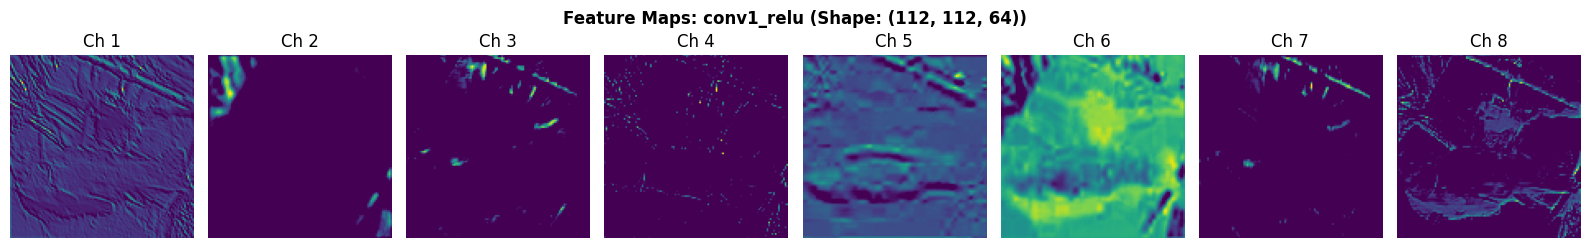

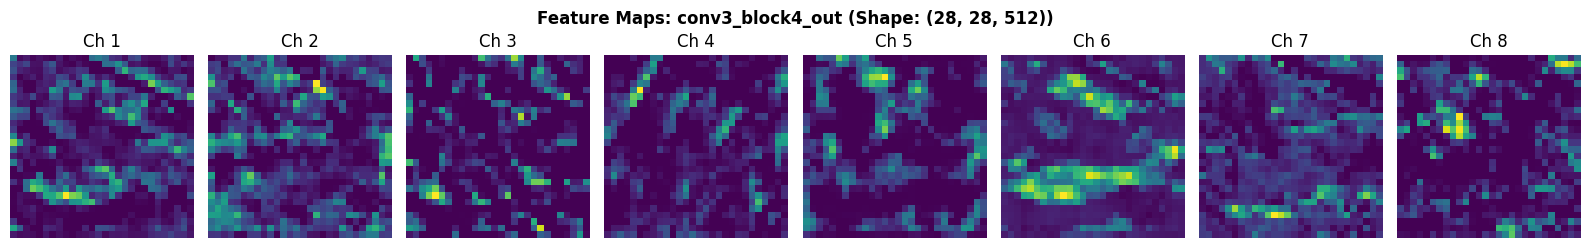

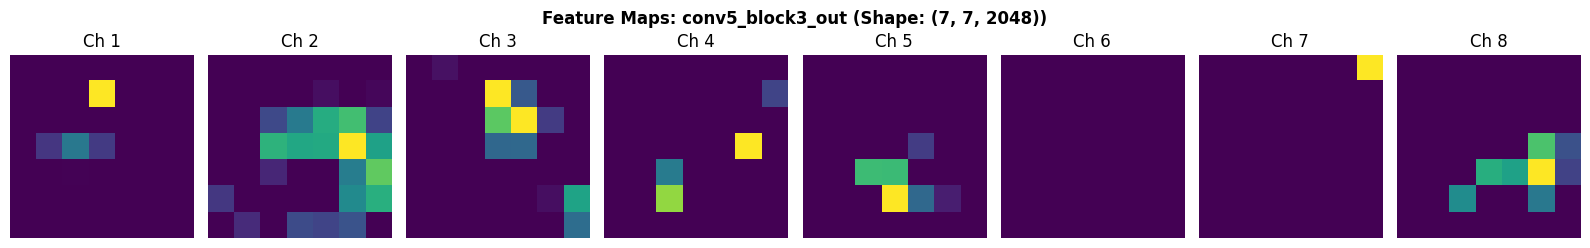

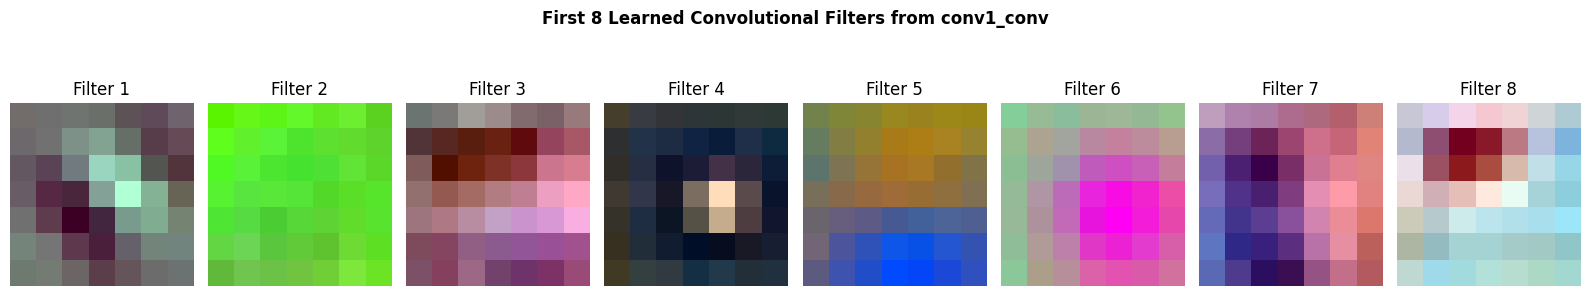

=== INTERPRETATION OF LEARNED REPRESENTATIONS ===
1. Shallow Layers (e.g., conv1_relu): Focus heavily on fine-grained spatial details, edges, textures, and basic gradients.
2. Mid-level Layers (e.g., conv3_block4_out): Capture complex textures, motifs, part-like shapes, and structural outlines.
3. Deep Layers (e.g., conv5_block3_out): Capture highly abstract, class-specific concepts while losing precise spatial layout.


In [ ]:
```python
# ============================================================
# QUESTION 2: CNN FILTERS AND FEATURE MAP VISUALIZATION
# ============================================================

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.utils import load_img, img_to_array

# ------------------------------------------------------------
# 1. ACCESS LOCAL DATASET AND CLASS MAPPINGS
# ------------------------------------------------------------

DATASET_DIR = "ImageNet/dataset"
MAPPING_FILE = "ImageNet/class_mapping.json"
IMG_SIZE = (224, 224)

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_DIR}"
    )

if not os.path.isfile(MAPPING_FILE):
    raise FileNotFoundError(
        f"Class mapping JSON file not found: {MAPPING_FILE}"
    )

with open(MAPPING_FILE, "r") as file:
    label_mapping = json.load(file)

np.random.seed(42)
tf.random.set_seed(42)


# ------------------------------------------------------------
# 2. COLLECT IMAGE PATHS AND CLASS LABELS
# ------------------------------------------------------------

def collect_images(directory):
    paths = []
    labels = []

    for class_folder in sorted(os.listdir(directory)):
        class_path = os.path.join(directory, class_folder)

        if not os.path.isdir(class_path):
            continue

        class_name = label_mapping.get(class_folder, class_folder)

        for filename in sorted(os.listdir(class_path)):
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            ):
                paths.append(os.path.join(class_path, filename))
                labels.append(class_name)

    return paths, labels


X_test_paths, y_test = collect_images(DATASET_DIR)

if len(X_test_paths) == 0:
    raise ValueError("No images found in the dataset directory.")


# ------------------------------------------------------------
# 3. IMAGE PREPROCESSING
# ------------------------------------------------------------

def load_preprocess_image(path):
    image = load_img(path, target_size=IMG_SIZE)
    image = img_to_array(image)
    image = np.expand_dims(image, axis=0)
    image = preprocess_input(image)

    return image


# ------------------------------------------------------------
# 4. LOAD PRETRAINED RESNET50 AND SELECT LAYERS
# ------------------------------------------------------------

cnn_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

cnn_model.trainable = False

layer_names = [
    "conv1_relu",
    "conv3_block4_out",
    "conv5_block3_out"
]


# ------------------------------------------------------------
# OUTPUT 1: LAYER NAMES AND FEATURE-MAP DIMENSIONS
# ------------------------------------------------------------

print("=== LAYER NAMES & FEATURE-MAP DIMENSIONS ===")

for name in layer_names:
    output_shape = cnn_model.get_layer(name).output.shape

    print(
        f"Layer Name: {name:<20} | "
        f"Height: {output_shape[1]:<4} | "
        f"Width: {output_shape[2]:<4} | "
        f"Channels: {output_shape[3]}"
    )

print()


# ------------------------------------------------------------
# 5. EXTRACT FEATURE MAPS
# ------------------------------------------------------------

# Select an image from the local dataset
image_index = np.random.randint(len(X_test_paths))
image_path = X_test_paths[image_index]
original_label = y_test[image_index]

image = load_preprocess_image(image_path)

print("Selected image:", image_path)
print("Original class label:", original_label)
print()

outputs = [
    cnn_model.get_layer(name).output
    for name in layer_names
]

feature_model = Model(
    inputs=cnn_model.input,
    outputs=outputs
)

feature_maps = feature_model.predict(image, verbose=0)


# ------------------------------------------------------------
# OUTPUT 2: FEATURE-MAP VISUALIZATIONS
# ------------------------------------------------------------

for name, feature in zip(layer_names, feature_maps):
    num_features = min(8, feature.shape[-1])

    plt.figure(figsize=(16, 2.5))

    plt.suptitle(
        f"Feature Maps: {name} (Shape: {feature.shape[1:]})",
        fontsize=12,
        fontweight="bold"
    )

    for i in range(num_features):
        plt.subplot(1, num_features, i + 1)

        plt.imshow(feature[0, :, :, i], cmap="viridis")
        plt.title(f"Ch {i + 1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# OUTPUT 3: FILTER VISUALIZATIONS
# ------------------------------------------------------------

layer = cnn_model.get_layer("conv1_conv")
filters, biases = layer.get_weights()

plt.figure(figsize=(16, 3.5))

plt.suptitle(
    "First 8 Learned Convolutional Filters from conv1_conv",
    fontsize=12,
    fontweight="bold"
)

for i in range(8):
    f = filters[:, :, :, i]

    f = (f - f.min()) / (f.max() - f.min() + 1e-8)

    plt.subplot(1, 8, i + 1)
    plt.imshow(f)
    plt.title(f"Filter {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# OUTPUT 4: INTERPRETATION OF LEARNED REPRESENTATIONS
# ------------------------------------------------------------

print("=== INTERPRETATION OF LEARNED REPRESENTATIONS ===")

print(
    "1. Shallow Layers (e.g., conv1_relu): "
    "Focus heavily on fine-grained spatial details, edges, "
    "textures, and basic gradients."
)

print(
    "2. Mid-level Layers (e.g., conv3_block4_out): "
    "Capture complex textures, motifs, part-like shapes, "
    "and structural outlines."
)

print(
    "3. Deep Layers (e.g., conv5_block3_out): "
    "Capture highly abstract, class-specific concepts "
    "while losing precise spatial layout."
)
```

QN3

=== TRANSFER LEARNING EVALUATION ===
Feature-vector dimension: 2048
Classification accuracy: 0.9776
Precision: 0.9777
Recall: 0.9776
F1-score: 0.9774



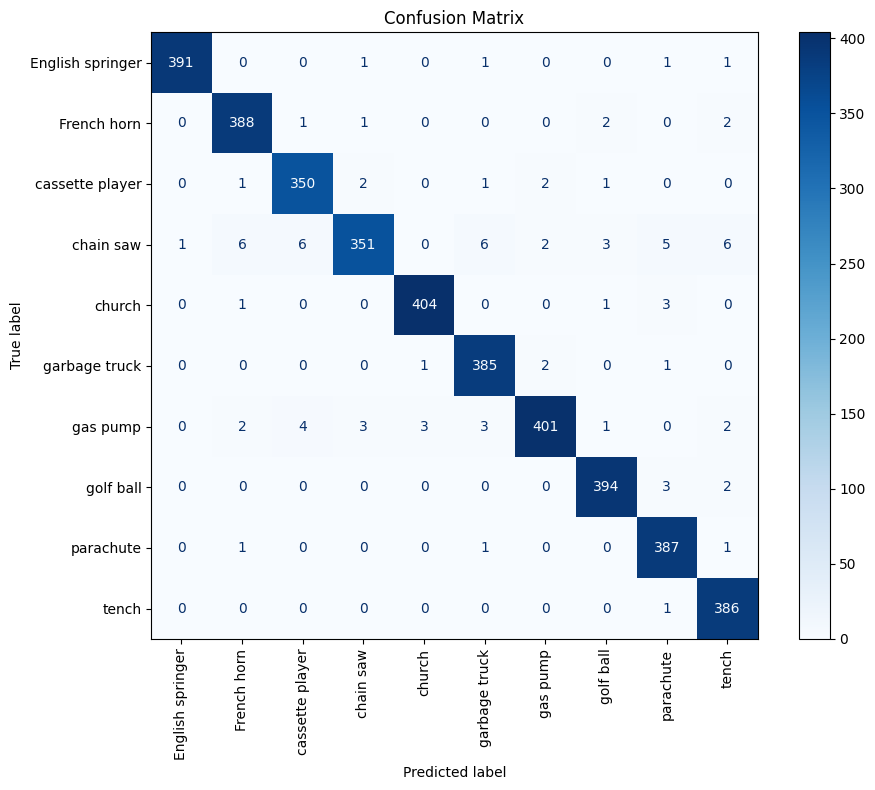

In [ ]:
# ============================================================
# QUESTION 3: TRANSFER LEARNING USING RESNET50
# ============================================================

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, GlobalAveragePooling2D
)
from tensorflow.keras import Sequential
from tensorflow.keras.utils import load_img, img_to_array

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. ACCESS LOCAL DATASET AND CLASS MAPPINGS
# ------------------------------------------------------------

DATASET_DIR = "ImageNet/dataset"
MAPPING_FILE = "ImageNet/class_mapping.json"
IMG_SIZE = (224, 224)

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_DIR}"
    )

if not os.path.isfile(MAPPING_FILE):
    raise FileNotFoundError(
        f"Class mapping JSON file not found: {MAPPING_FILE}"
    )

with open(MAPPING_FILE, "r") as file:
    label_mapping = json.load(file)

np.random.seed(42)
tf.random.set_seed(42)


# ------------------------------------------------------------
# 2. COLLECT IMAGE PATHS AND CLASS LABELS
# ------------------------------------------------------------

def collect_images(directory):
    paths = []
    labels = []

    for class_folder in sorted(os.listdir(directory)):
        class_path = os.path.join(directory, class_folder)

        if not os.path.isdir(class_path):
            continue

        class_name = label_mapping.get(class_folder, class_folder)

        for filename in sorted(os.listdir(class_path)):
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            ):
                paths.append(os.path.join(class_path, filename))
                labels.append(class_name)

    return paths, labels


X_image_paths, y_labels = collect_images(DATASET_DIR)

if len(X_image_paths) == 0:
    raise ValueError("No images found in the dataset directory.")

if len(set(y_labels)) < 2:
    raise ValueError("At least two classes are required for classification.")

print("Total images:", len(X_image_paths))
print("Total classes:", len(set(y_labels)))
print()


# ------------------------------------------------------------
# 3. SPLIT DATA INTO TRAINING AND TESTING SETS
# ------------------------------------------------------------

X_train_paths, X_test_paths, y_train, y_test = train_test_split(
    X_image_paths,
    y_labels,
    test_size=0.2,
    random_state=42,
    stratify=y_labels
)


# ------------------------------------------------------------
# 4. LOAD PRETRAINED RESNET50
# ------------------------------------------------------------

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

feature_extractor = Sequential([
    base_model,
    GlobalAveragePooling2D()
])


# ------------------------------------------------------------
# 5. PREPROCESS IMAGES
# ------------------------------------------------------------

def preprocess_image(path):
    image = load_img(path, target_size=IMG_SIZE)
    image = img_to_array(image)
    image = preprocess_input(image)

    return image


# ------------------------------------------------------------
# 6. EXTRACT FEATURES IN BATCHES
# ------------------------------------------------------------

def extract_features(paths, batch_size=32):
    features = []

    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start:start + batch_size]

        batch_images = np.stack([
            preprocess_image(path)
            for path in batch_paths
        ])

        batch_features = feature_extractor.predict(
            batch_images,
            verbose=0
        )

        features.append(batch_features)

    return np.concatenate(features, axis=0).astype(np.float32)


X_train_features = extract_features(X_train_paths)
X_test_features = extract_features(X_test_paths)


# ------------------------------------------------------------
# 7. ENCODE CLASS LABELS
# ------------------------------------------------------------

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

class_names = label_encoder.classes_
num_classes = len(class_names)


# ------------------------------------------------------------
# 8. SPLIT TRAINING FEATURES INTO TRAIN AND VALIDATION SETS
# ------------------------------------------------------------

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_features,
    y_train_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_train_encoded
)


# ------------------------------------------------------------
# 9. BUILD A NEW CLASSIFICATION LAYER
# ------------------------------------------------------------

classifier = Sequential([
    Input(shape=(2048,)),
    Dense(256, activation="relu"),
    Dropout(0.4),
    Dense(num_classes, activation="softmax")
])

classifier.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ------------------------------------------------------------
# 10. TRAIN THE CLASSIFIER
# ------------------------------------------------------------

history = classifier.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=0
)


# ------------------------------------------------------------
# 11. TEST THE CLASSIFIER AND EVALUATE
# ------------------------------------------------------------

probabilities = classifier.predict(
    X_test_features,
    verbose=0
)

y_pred = np.argmax(probabilities, axis=1)

accuracy = accuracy_score(y_test_encoded, y_pred)

precision = precision_score(
    y_test_encoded,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test_encoded,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test_encoded,
    y_pred,
    average="weighted",
    zero_division=0
)


# ------------------------------------------------------------
# OUTPUT 1: TRANSFER LEARNING EVALUATION
# ------------------------------------------------------------

print("=== TRANSFER LEARNING EVALUATION ===")
print(f"Feature-vector dimension: {X_train_features.shape[1]}")
print(f"Number of classes: {num_classes}")
print(f"Classification accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print()


# ------------------------------------------------------------
# OUTPUT 2: CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_encoded,
    y_pred,
    labels=np.arange(num_classes)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# OUTPUT 3: TRAINING AND VALIDATION ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

QN4

Training images: 1000
Validation images: 200

ResNet50 loaded successfully.
Feature dimension: 2048

Training feature shape: (1000, 2048)
Testing feature shape: (200, 2048)

Sample caption: <start> a photo of a tench <end>
Vocabulary size: 23
Maximum caption length: 8


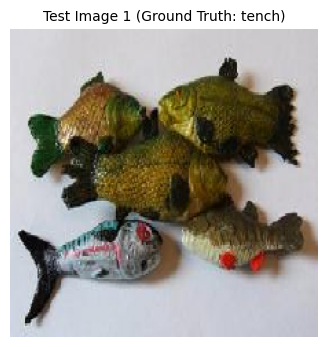

Original Image
 ↓
CNN Feature Vector (Tensor shape (2048,))
 ↓
LSTM
 ↓
Generated Caption:
"A photo of a tench."


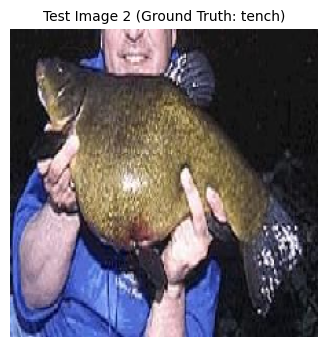

Original Image
 ↓
CNN Feature Vector (Tensor shape (2048,))
 ↓
LSTM
 ↓
Generated Caption:
"A photo of a tench."


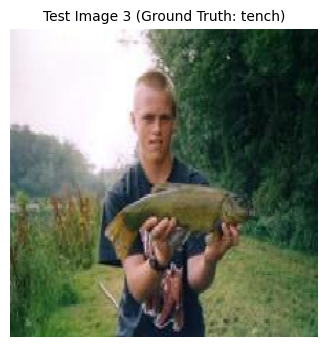

Original Image
 ↓
CNN Feature Vector (Tensor shape (2048,))
 ↓
LSTM
 ↓
Generated Caption:
"A photo of a tench."


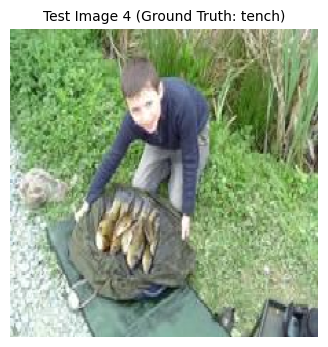

Original Image
 ↓
CNN Feature Vector (Tensor shape (2048,))
 ↓
LSTM
 ↓
Generated Caption:
"A photo of a tench."


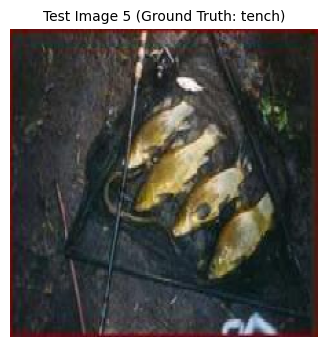

Original Image
 ↓
CNN Feature Vector (Tensor shape (2048,))
 ↓
LSTM
 ↓
Generated Caption:
"A photo of a tench."


In [ ]:
# ============================================================
# QUESTION 4: IMAGE CAPTION GENERATION USING CNN AND LSTM
# ============================================================

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, LSTM, Embedding
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import load_img, img_to_array

# ------------------------------------------------------------
# 1. ACCESS LOCAL DATASET DIRECTORY
# ------------------------------------------------------------

DATASET_DIR = "ImageNet/dataset"
MAPPING_FILE = "ImageNet/class_mapping.json"

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_DIR}"
    )

if not os.path.isfile(MAPPING_FILE):
    raise FileNotFoundError(
        f"Class mapping JSON file not found: {MAPPING_FILE}"
    )

with open(MAPPING_FILE, "r") as file:
    label_mapping = json.load(file)

IMG_SIZE = (224, 224)

np.random.seed(42)
tf.random.set_seed(42)
rng = np.random.default_rng(42)

MAX_TRAIN_PER_CLASS = 100
MAX_TEST_PER_CLASS = 20

# ------------------------------------------------------------
# 2. LOAD IMAGE PATHS AND CLASS LABELS
# ------------------------------------------------------------

def collect_images(directory):
    train_paths = []
    train_labels = []
    test_paths = []
    test_labels = []

    for folder in sorted(os.listdir(directory)):
        folder_path = os.path.join(directory, folder)

        if not os.path.isdir(folder_path):
            continue

        files = [
            os.path.join(folder_path, filename)
            for filename in sorted(os.listdir(folder_path))
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        ]

        if not files:
            continue

        # Randomly select images from each class
        rng.shuffle(files)

        count = min(
            MAX_TRAIN_PER_CLASS + MAX_TEST_PER_CLASS,
            len(files)
        )

        selected = files[:count]

        train_count = min(MAX_TRAIN_PER_CLASS, len(selected))
        class_name = label_mapping.get(folder, folder)

        train_files = selected[:train_count]
        test_files = selected[train_count:]

        train_paths.extend(train_files)
        train_labels.extend([class_name] * len(train_files))

        test_paths.extend(test_files)
        test_labels.extend([class_name] * len(test_files))

    return train_paths, train_labels, test_paths, test_labels


X_train_paths, y_train, X_test_paths, y_test = collect_images(
    DATASET_DIR
)

if not X_train_paths or not X_test_paths:
    raise ValueError(
        "Insufficient images found. Ensure each class contains "
        "more than MAX_TRAIN_PER_CLASS images."
    )

print("Training images:", len(X_train_paths))
print("Validation images:", len(X_test_paths))

# ------------------------------------------------------------
# 3. LOAD PRETRAINED RESNET50 CNN
# ------------------------------------------------------------

cnn = ResNet50(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

cnn.trainable = False

print("\nResNet50 loaded successfully.")
print("Feature dimension:", cnn.output_shape[-1])

# ------------------------------------------------------------
# 4. IMAGE PREPROCESSING
# ------------------------------------------------------------

def preprocess_image(path):
    image = load_img(path, target_size=(224, 224))
    image = img_to_array(image)
    image = preprocess_input(image)

    return image

# ------------------------------------------------------------
# 5. EXTRACT CNN FEATURES IN BATCHES
# ------------------------------------------------------------

def extract_features(paths, batch_size=32):
    all_features = []

    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start:start + batch_size]

        batch_images = np.stack([
            preprocess_image(path)
            for path in batch_paths
        ])

        features = cnn.predict(batch_images, verbose=0)
        all_features.append(features)

    return np.concatenate(all_features, axis=0).astype(np.float32)


train_features = extract_features(X_train_paths)
test_features = extract_features(X_test_paths)

print("\nTraining feature shape:", train_features.shape)
print("Testing feature shape:", test_features.shape)

# ------------------------------------------------------------
# 6. CONVERT CLASS LABELS INTO CAPTIONS
# ------------------------------------------------------------

START_TOKEN = "<start>"
END_TOKEN = "<end>"

def create_caption(class_name):
    return f"{START_TOKEN} a photo of a {class_name} {END_TOKEN}"


train_captions = [
    create_caption(label) for label in y_train
]

test_captions = [
    create_caption(label) for label in y_test
]

print("\nSample caption:", train_captions[0])

# ------------------------------------------------------------
# 7. TOKENIZE CAPTIONS AND BUILD VOCABULARY
# ------------------------------------------------------------

tokenizer = Tokenizer(filters="", lower=True, split=" ")
tokenizer.fit_on_texts(train_captions)

vocab_size = len(tokenizer.word_index) + 1

train_sequences = tokenizer.texts_to_sequences(train_captions)
test_sequences = tokenizer.texts_to_sequences(test_captions)

max_length = max(
    len(sequence) for sequence in train_sequences
)

train_padded = pad_sequences(
    train_sequences,
    maxlen=max_length,
    padding="post"
)

test_padded = pad_sequences(
    test_sequences,
    maxlen=max_length,
    padding="post"
)

print("Vocabulary size:", vocab_size)
print("Maximum caption length:", max_length)

# ------------------------------------------------------------
# 8. PREPARE NEXT-WORD TRAINING SEQUENCES
# ------------------------------------------------------------

decoder_input_train = train_padded[:, :-1]
decoder_target_train = train_padded[:, 1:]

decoder_input_test = test_padded[:, :-1]
decoder_target_test = test_padded[:, 1:]

train_weights = (
    decoder_target_train != 0
).astype(np.float32)

test_weights = (
    decoder_target_test != 0
).astype(np.float32)

# ------------------------------------------------------------
# 9. BUILD CNN-LSTM CAPTION GENERATION MODEL
# ------------------------------------------------------------

feature_dim = train_features.shape[1]
embedding_dim = 256
lstm_units = 256

image_input = Input(
    shape=(feature_dim,),
    name="image_features"
)

caption_input = Input(
    shape=(max_length - 1,),
    dtype="int32",
    name="caption_sequence"
)

initial_h = Dense(
    lstm_units,
    activation="tanh",
    name="image_hidden_state"
)(image_input)

initial_c = Dense(
    lstm_units,
    activation="tanh",
    name="image_cell_state"
)(image_input)

word_embeddings = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    mask_zero=True,
    name="word_embedding"
)(caption_input)

decoder = LSTM(
    lstm_units,
    return_sequences=True,
    name="caption_lstm"
)(
    word_embeddings,
    initial_state=[initial_h, initial_c]
)

output = Dense(
    vocab_size,
    activation="softmax",
    name="word_prediction"
)(decoder)

model = Model(
    inputs=[image_input, caption_input],
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy"
)

# ------------------------------------------------------------
# 10. TRAIN THE CNN-LSTM MODEL
# ------------------------------------------------------------

history = model.fit(
    [train_features, decoder_input_train],
    decoder_target_train,
    sample_weight=train_weights,
    validation_data=(
        [test_features, decoder_input_test],
        decoder_target_test,
        test_weights
    ),
    epochs=15,
    batch_size=32,
    verbose=0
)

# ------------------------------------------------------------
# 11. CAPTION GENERATION
# ------------------------------------------------------------

start_id = tokenizer.word_index[START_TOKEN]
end_id = tokenizer.word_index[END_TOKEN]

def generate_caption(feature, max_words=20):
    sequence = [start_id]

    for _ in range(max_words):
        padded_sequence = pad_sequences(
            [sequence],
            maxlen=max_length - 1,
            padding="post"
        )

        predictions = model.predict(
            [feature.reshape(1, -1), padded_sequence],
            verbose=0
        )

        timestep = len(sequence) - 1

        next_word_id = int(
            np.argmax(predictions[0, timestep, :])
        )

        if next_word_id == 0 or next_word_id == end_id:
            break

        sequence.append(next_word_id)

    words = [
        tokenizer.index_word.get(token, "")
        for token in sequence[1:]
    ]

    return " ".join(words).strip().capitalize() + "."

# ------------------------------------------------------------
# 12. DISPLAY IMAGES AND WORKFLOW
# ------------------------------------------------------------

num_samples = min(5, len(X_test_paths))

for i in range(num_samples):

    feature_vector_summary = (
        f"Tensor shape {test_features[i].shape}"
    )

    generated_caption = generate_caption(test_features[i])

    # Display original image
    original_image = load_img(
        X_test_paths[i],
        target_size=(224, 224)
    )

    plt.figure(figsize=(4, 4))
    plt.imshow(original_image)

    plt.title(
        f"Test Image {i + 1} (Ground Truth: {y_test[i]})",
        fontsize=10
    )

    plt.axis("off")
    plt.show()

    # Display workflow
    print("Original Image")
    print(" ↓")
    print(f"CNN Feature Vector ({feature_vector_summary})")
    print(" ↓")
    print("LSTM")
    print(" ↓")
    print("Generated Caption:")
    print(f'"{generated_caption}"')
    print("=" * 60)

QN5

Dataset shape: (1000, 64, 64, 3)
Number of descriptions: 1000
Classes: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']
Generator output shape: (None, 64, 64, 3)
Epoch 0: Discriminator Loss = 0.7044, Generator Loss = 0.6862
Epoch 10: Discriminator Loss = 0.2625, Generator Loss = 1.3937
Epoch 20: Discriminator Loss = 0.1618, Generator Loss = 3.9232
Epoch 30: Discriminator Loss = 0.1945, Generator Loss = 9.9279
Epoch 40: Discriminator Loss = 0.1890, Generator Loss = 12.4724
Epoch 50: Discriminator Loss = 0.2111, Generator Loss = 16.7506
Epoch 60: Discriminator Loss = 0.2055, Generator Loss = 15.7084
Epoch 70: Discriminator Loss = 0.1844, Generator Loss = 14.0315
Epoch 80: Discriminator Loss = 0.1646, Generator Loss = 12.8795
Epoch 90: Discriminator Loss = 0.1551, Generator Loss = 13.0787


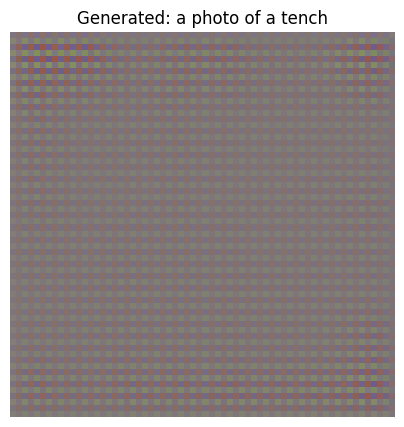

"a photo of a tench"
 ↓
Conditional GAN
 ↓
Generated Image


In [ ]:
# ============================================================
# QUESTION 5: TEXT-CONDITIONED GAN FOR IMAGE GENERATION
# ============================================================

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

# 1. Access local ImageNet dataset

DATASET_PATH = "ImageNet/dataset"
MAPPING_FILE = "ImageNet/class_mapping.json"

if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_PATH}")

if not os.path.isfile(MAPPING_FILE):
    raise FileNotFoundError(f"Class mapping file not found: {MAPPING_FILE}")

with open(MAPPING_FILE, "r") as file:
    label_mapping = json.load(file)

classes = sorted([
    cls for cls in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, cls))
])

X, texts = [], []

MAX_IMAGES_PER_CLASS = 100

for cls in classes:
    folder = os.path.join(DATASET_PATH, cls)
    class_name = label_mapping.get(cls, cls.replace("_", " "))

    files = [
        f for f in sorted(os.listdir(folder))
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ][:MAX_IMAGES_PER_CLASS]

    for file in files:
        try:
            img_path = os.path.join(folder, file)

            img = load_img(img_path, target_size=(64, 64))
            img = img_to_array(img)

            X.append(img / 127.5 - 1.0)
            texts.append("a photo of a " + class_name)

        except Exception:
            continue

X = np.array(X, dtype=np.float32)
texts = np.array(texts)

print("Dataset shape:", X.shape)
print("Number of descriptions:", len(texts))
print("Classes:", classes)

if len(X) == 0:
    raise ValueError("No images found. Check the dataset path.")

# 2. Tokenize text descriptions

tokenizer = Tokenizer()
tokenizer.fit_on_texts(texts)

seq = pad_sequences(
    tokenizer.texts_to_sequences(texts),
    maxlen=6,
    padding="post"
)

vocab_size = len(tokenizer.word_index) + 1

# 3. Text encoder

ti = Input(shape=(6,))
te = Embedding(vocab_size, 32)(ti)
te = GlobalAveragePooling1D()(te)

text_encoder = Model(ti, te)

text_features = text_encoder.predict(seq, verbose=0)

# 4. Conditional Generator: Noise + Text -> Image

noise_input = Input(shape=(100,))
text_input = Input(shape=(32,))

g = Concatenate()([noise_input, text_input])
g = Dense(8 * 8 * 128, activation="relu")(g)
g = Reshape((8, 8, 128))(g)

# 8x8 -> 16x16
g = Conv2DTranspose(
    64, 4, strides=2,
    padding="same", activation="relu"
)(g)

# 16x16 -> 32x32
g = Conv2DTranspose(
    32, 4, strides=2,
    padding="same", activation="relu"
)(g)

# 32x32 -> 64x64
g = Conv2DTranspose(
    16, 4, strides=2,
    padding="same", activation="relu"
)(g)

generated_image = Conv2D(
    3, 3, padding="same", activation="tanh"
)(g)

generator = Model(
    [noise_input, text_input],
    generated_image
)

print("Generator output shape:", generator.output_shape)

# 5. Conditional Discriminator: Image + Text -> Real/Fake

image_input = Input(shape=(64, 64, 3))
text_input_d = Input(shape=(32,))

d = Conv2D(64, 4, strides=2, padding="same")(image_input)
d = LeakyReLU(negative_slope=0.2)(d)

d = Conv2D(128, 4, strides=2, padding="same")(d)
d = LeakyReLU(negative_slope=0.2)(d)

d = Flatten()(d)
d = Concatenate()([d, text_input_d])

validity = Dense(1, activation="sigmoid")(d)

discriminator = Model(
    [image_input, text_input_d],
    validity
)

discriminator.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

# 6. Build combined GAN

discriminator.trainable = False

noise_gan = Input(shape=(100,))
text_gan = Input(shape=(32,))

fake = generator([noise_gan, text_gan])
valid = discriminator([fake, text_gan])

gan = Model([noise_gan, text_gan], valid)

gan.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

# 7. Train Generator and Discriminator

epochs = 100
batch_size = min(32, len(X))

if batch_size == 0:
    raise ValueError("The dataset contains no usable images.")

real_labels = np.ones((batch_size, 1), dtype=np.float32)
fake_labels = np.zeros((batch_size, 1), dtype=np.float32)

for epoch in range(epochs):

    idx = np.random.randint(0, len(X), batch_size)

    real_images = X[idx]
    real_text = text_features[idx]

    noise = np.random.normal(
        0, 1, (batch_size, 100)
    ).astype(np.float32)

    fake_images = generator.predict(
        [noise, real_text], verbose=0
    )

    # Train discriminator
    discriminator.trainable = True

    d_loss_real = discriminator.train_on_batch(
        [real_images, real_text], real_labels
    )

    d_loss_fake = discriminator.train_on_batch(
        [fake_images, real_text], fake_labels
    )

    # Train generator
    discriminator.trainable = False

    g_loss = gan.train_on_batch(
        [noise, real_text], real_labels
    )

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch}: "
            f"Discriminator Loss = "
            f"{(float(d_loss_real) + float(d_loss_fake)) / 2:.4f}, "
            f"Generator Loss = {float(g_loss):.4f}"
        )

# 8. Generate an image from a text description

def generate_image(description):

    s = pad_sequences(
        tokenizer.texts_to_sequences([description]),
        maxlen=6,
        padding="post"
    )

    feature = text_encoder.predict(s, verbose=0)

    noise = np.random.normal(
        0, 1, (1, 100)
    ).astype(np.float32)

    img = generator.predict(
        [noise, feature], verbose=0
    )[0]

    img = (img + 1.0) / 2.0

    return np.clip(img, 0, 1)


description = "a photo of a tench"
generated = generate_image(description)

# 9. Display only the single generated image

plt.figure(figsize=(5, 5))
plt.imshow(generated)
plt.title("Generated: " + description)
plt.axis("off")
plt.show()

# 10. Print the text-based pipeline representation

print(f'"{description}"')
print(" ↓")
print("Conditional GAN")
print(" ↓")
print("Generated Image")

EXP 1
## Objective
To preprocess images from a local ImageNet dataset, perform image classification using a pretrained ResNet50 CNN, and analyse its predictions.

## 1. Dataset Loading
Images are stored in class-specific folders inside `ImageNet/dataset`. A JSON mapping file converts folder IDs into readable class names. The program collects image paths and their corresponding labels, then displays the total number of images, the number of classes, and sample labels.

## 2. Image Preprocessing
A selected image is resized to 224 × 224 pixels and converted into a NumPy array. Its initial shape is `(224, 224, 3)`, representing height, width, and RGB channels.

`np.expand_dims()` adds a batch dimension, producing `(1, 224, 224, 3)`. The `preprocess_input()` function then converts the image into the representation expected by ResNet50: RGB is converted to BGR, and channel-specific means are subtracted.

Correct preprocessing is important because the pretrained model expects inputs prepared in the same way as during its original training.

## 3. Sample Image Visualisation
Five random images are displayed with their dataset labels. This checks whether the images load correctly and whether their labels appear appropriate.

## 4. ResNet50 Model
ResNet50 is a 50-layer-class deep Convolutional Neural Network with pretrained ImageNet weights. The argument `include_top=True` retains its original classification head, which predicts among 1,000 ImageNet classes.

The CNN processes images through convolutional layers, activation functions, and residual blocks. Early layers learn simple visual patterns such as edges and textures, while deeper layers learn more complex patterns associated with objects.

ResNet50 uses residual connections, which add a block's input to its transformed output:

**y = F(x) + x**

These connections improve information and gradient flow through a deep network.

## 5. Image Classification
A random image is selected and passed to `model.predict()`. The model performs inference using its existing weights; it does not train or update them.

The standard classification head produces scores for 1,000 classes. `decode_predictions(predictions, top=5)` converts the five highest-scoring results into readable class names and probabilities.

## 6. Prediction Analysis
The program displays the original dataset label, the top-five predicted classes, and their probabilities. The original label comes from the local dataset, whereas the predictions come from ResNet50's built-in ImageNet classification system.

The program also prints the processed image's shape, data type, minimum value, and maximum value. Negative pixel values are expected because ResNet50 preprocessing subtracts channel means.

## Outputs
- Five sample images with labels.
- Original class label.
- Top-five predicted classes and probabilities.
- Preprocessed image statistics.

## Key Understanding
This experiment demonstrates image preprocessing and inference using a pretrained CNN. The JSON mapping does not add new classes to ResNet50, and the highest-scoring prediction is not guaranteed to be correct. The program does not calculate overall dataset accuracy.

EXP 2

## Objective
To visualise convolutional filters and intermediate feature maps from a pretrained ResNet50 model and understand how a CNN learns visual representations.

## 1. Dataset Loading and Preprocessing
An image is selected from the local ImageNet dataset. Its folder ID is converted into a readable label using the JSON mapping file.

The image is resized to 224 × 224 pixels, converted into a NumPy array, expanded to include a batch dimension, and preprocessed using ResNet50's `preprocess_input()` function.

## 2. Loading ResNet50
ResNet50 is loaded with pretrained ImageNet weights. When `include_top=False` is used, the original classification head is removed, allowing the convolutional layers to be examined as a feature extractor.

The model's learned convolutional filters are retained. The experiment investigates what these filters contain and what activations they produce when processing an image.

## 3. Understanding Convolutional Filters
A convolutional filter is a small matrix of learnable weights that moves across an image or feature map. At each position, it performs calculations on the local input values to produce an output.

During training, filters learn to respond to useful patterns. Early filters often respond to edges, lines, orientations, and colour transitions.

Visualising a filter means inspecting its learned weight values. It does not directly show the exact image pattern that the filter will detect in every situation; its response also depends on the input and the surrounding network operations.

## 4. Understanding Feature Maps
A feature map is the activation produced when an input passes through a layer. It indicates how strongly the layer's filters respond at different spatial locations.

The program selects intermediate layers from different depths of ResNet50 and constructs a model that returns their outputs.

The image is passed through the network, and the selected activations are extracted and visualised.

## 5. Comparing Different Network Depths
- **Early layers:** Usually respond to simple patterns such as edges and textures. They tend to retain more spatial detail.
- **Intermediate layers:** Combine basic patterns into more complex shapes and structures.
- **Deep layers:** Represent more abstract combinations of visual features associated with object parts and semantic categories.

As the network becomes deeper, feature-map spatial dimensions generally decrease while the number of feature channels often increases.

Residual connections help information and gradients flow through ResNet50's deep architecture.

## Outputs
- Visualisations of selected convolutional filters.
- Feature maps from early, intermediate, and deep layers.
- Feature-map shapes, if printed by the code.

## Key Understanding
A filter contains learned weights; a feature map contains the activations produced by applying the network to an input. Filter visualisation examines the learned parameters, whereas feature-map visualisation examines the network's response to a particular image.

The experiment helps explain how CNNs progressively transform raw pixels into increasingly complex visual representations.

EXP 3

## Objective
To use a pretrained ResNet50 model as a feature extractor and train a new classification layer to classify images into the target dataset's classes.

## 1. Dataset Preparation
Images are collected from the local ImageNet directory, and class folder IDs are converted into readable labels using the JSON mapping file.

The images are divided into training and evaluation subsets. The training data is used to fit the classifier, while the held-out data is used to assess its performance.

## 2. Image Preprocessing
Each image is resized to 224 × 224 pixels and processed using ResNet50's `preprocess_input()` function. This ensures that the images use the input representation expected by the pretrained network.

## 3. Feature Extraction with ResNet50
ResNet50 is loaded with pretrained ImageNet weights and `include_top=False`. The original 1,000-class classification head is removed, and the convolutional feature extractor is kept frozen.

Freezing the feature extractor means that its pretrained weights are not updated during training.

The final feature maps are passed through Global Average Pooling. This operation averages each feature channel across its spatial dimensions, producing a compact feature vector. For the standard ResNet50 convolutional output, this vector has 2,048 features.

These features provide a numerical representation of the image that the new classifier can learn from.

## 4. Training the New Classifier
A new Dense layer is added to map the extracted feature vectors to the target classes. If the target dataset contains 10 classes, the classifier produces 10 output scores.

During training, the classifier learns to associate ResNet50's visual features with the target labels. The frozen convolutional weights remain unchanged.

This is transfer learning: knowledge learned from a large source dataset is reused for a different classification task.

## 5. Prediction and Evaluation
The trained classifier predicts labels for images in the evaluation subset. Predicted labels are compared with the actual labels to calculate performance metrics.

- **Accuracy:** Fraction of predictions that are correct.
- **Precision:** Among predictions assigned to a class, the fraction that actually belongs to that class.
- **Recall:** Among examples belonging to a class, the fraction correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **Confusion matrix:** Table comparing actual classes with predicted classes, showing which categories are correctly classified or confused with others.

When weighted precision, recall, and F1-score are used, each class's contribution is weighted according to its number of true examples.

## Outputs
- Classification accuracy.
- Weighted precision, recall, and F1-score.
- Confusion matrix.

## Key Understanding
Transfer learning reduces the need to train a large CNN from scratch. ResNet50 extracts pretrained visual features, while a new classification layer learns the target categories.

The classifier's performance depends on the quality of the dataset, the training procedure, the class mapping, and whether the evaluation data is representative. The evaluation set should remain separate from the training data.

EXP 4

## Objective
To generate a text caption for an image by combining a Convolutional Neural Network (CNN) for visual feature extraction with a Long Short-Term Memory (LSTM) network for sequential word prediction.

## 1. Dataset Preparation
Images are loaded from the local ImageNet dataset. Folder IDs are mapped to readable class names using the JSON mapping file.

The program creates template captions such as "a photo of a tench". Special tokens, such as <start> and <end>, mark the beginning and end of each caption.

These captions are generated from class labels rather than written by humans. Therefore, the experiment demonstrates a simplified image-captioning task.

## 2. CNN: Extracting Image Features
A pretrained ResNet50 CNN processes each image and extracts visual features.

The CNN learns visual patterns such as edges, textures, shapes, and object-related structures. Its output is a numerical representation of the image.

The CNN answers: "What visual information can be extracted from this image?"

These features provide visual context for the caption-generation model.

## 3. Text Tokenisation
The captions are converted into sequences of integer tokens using a tokenizer. Each distinct word is assigned a numerical index.

For example, a caption might be represented as:

"a photo of a tench"

The tokenizer converts the words into numbers. Padding ensures that the sequences have compatible lengths.

During training, the model learns to predict the next word using the preceding words and image-related information.

## 4. How LSTM Works
LSTM stands for Long Short-Term Memory. It is a type of recurrent neural network (RNN) designed to learn relationships across sequences.

Unlike a standard feed-forward network, an LSTM maintains information from earlier time steps. It uses a cell state, a hidden state, and three gates to control information flow.

**Cell state (Cₜ):** Carries information through the sequence and acts as the LSTM's memory.

**Hidden state (hₜ):** Represents the current output or hidden representation, which is used to predict the next word and passed to the next time step.

The three gates are:

1. **Forget gate:** Decides how much of the previous cell state to retain.
   fₜ = σ(Wf · [hₜ₋₁, xₜ] + bf)

2. **Input gate:** Controls how much new information is written into memory.
   iₜ = σ(Wi · [hₜ₋₁, xₜ] + bi)

   A candidate memory value is computed:
   C̃ₜ = tanh(Wc · [hₜ₋₁, xₜ] + bc)

3. **Output gate:** Controls how much of the updated memory is exposed as the hidden state.
   oₜ = σ(Wo · [hₜ₋₁, xₜ] + bo)

The cell state is updated as:

   Cₜ = fₜ × Cₜ₋₁ + iₜ × C̃ₜ

The hidden state is calculated as:

   hₜ = oₜ × tanh(Cₜ)

Here, xₜ is the current input, σ is the sigmoid function, and W and b represent learned weights and biases. The sigmoid function produces gate values between 0 and 1.

The forget gate removes or retains previous information, the input gate adds useful information, and the output gate determines what information is exposed. This mechanism helps LSTMs learn longer-term dependencies in sequences.

## 5. Training the Caption Model
The training process uses image features and tokenised captions. The LSTM learns to predict the next word from the preceding words and image-related context.

For example, the target sequence might be:

Input: <start> a photo of a
Target: a photo of a tench <end>

Training compares the predicted next-word distribution with the expected next word and adjusts the trainable model parameters.

## 6. Generating a Caption
For a test image, the CNN extracts its visual features. The caption-generation model starts with the <start> token and predicts a word.

The generated word is fed back into the model to predict the next word. This process repeats until the <end> token is generated or a maximum sequence length is reached.

The resulting sequence is converted from token IDs back into readable text and displayed with the image.

## Outputs
- Selected test images.
- Generated captions.
- Image-to-caption workflow, as displayed by the code.

## Key Understanding
The CNN extracts visual features, while the LSTM models the sequence of words. The LSTM's cell state, hidden state, and gates help it preserve relevant information and predict words in context.

Because this experiment uses class-name-based template captions, it demonstrates simplified caption generation rather than detailed natural-language descriptions of arbitrary scenes.

EXP 5

## Objective
To implement a text-conditioned Generative Adversarial Network (CGAN) that generates a synthetic image using a text description and a random noise vector.

## 1. Dataset Preparation
Images are loaded from the local ImageNet dataset. Folder IDs are mapped to readable class names using the JSON mapping file.

A limited number of images are loaded from each class and resized to 64 × 64 pixels. Pixel values are normalised from [0, 255] to [-1, 1]:

   x_normalised = (x / 127.5) - 1

This matches the range of the generator's tanh output.

Each image is associated with a template description, such as "a photo of a tench".

## 2. Text Encoding
The captions are converted into token sequences using a tokenizer. An Embedding layer converts each token into a 32-dimensional vector, and Global Average Pooling combines the token representations into a 32-dimensional text feature vector.

The text vector provides conditioning information about the desired image category.

In this implementation, the text encoder is used to calculate the text features before GAN training. It is not a pretrained language model, and it is not jointly trained through the GAN loss. Consequently, its word representations remain essentially random initial embeddings. This limits how effectively the text features can guide generation.

## 3. Generator: Creating Fake Images
The generator receives two inputs:

1. A random noise vector of length 100.
2. A 32-dimensional text feature vector.

The noise vector provides a source of variation, while the text vector is intended to provide information about the requested content.

The two vectors are concatenated and passed through a Dense layer. The output is reshaped into an 8 × 8 × 128 feature map.

Transposed convolutional layers progressively increase the spatial dimensions:

   8 × 8 → 16 × 16 → 32 × 32 → 64 × 64

A final convolution produces three colour channels, and tanh restricts the output values to [-1, 1].

The generator's goal is to produce images that look sufficiently realistic to fool the discriminator.

## 4. Discriminator: Distinguishing Real and Fake Images
The discriminator receives an image and its corresponding text feature vector.

Convolutional layers extract visual information from the image. The resulting feature representation is flattened and concatenated with the text vector.

A Dense layer with sigmoid activation produces a score between 0 and 1, representing the discriminator's estimate that the image is real.

The discriminator learns to distinguish real training images from generated images. It is intended to evaluate image realism in the context of the supplied text.

## 5. How Adversarial Training Works
GAN training involves two competing objectives.

**Discriminator training:**
- Real images are paired with target labels of 1.
- Generated images are paired with target labels of 0.
- The discriminator learns to distinguish real samples from generated samples.

**Generator training:**
- The generator creates images from random noise and text features.
- The generated images are passed through the discriminator.
- The generator is trained with target labels of 1, encouraging it to produce images that the discriminator classifies as real.

Binary cross-entropy measures the difference between the predicted real/fake scores and the target labels.

The generator and discriminator improve through this competition. The generator tries to fool the discriminator, while the discriminator tries to identify generated images.

The training loop periodically prints the discriminator and generator losses.

## 6. Generating an Image from Text
A requested description is tokenised and converted into text features. A new random noise vector is generated and combined with those features.

The trained generator produces a 64 × 64 RGB image. The image is rescaled from [-1, 1] to [0, 1] for display:

   x_display = (x_generated + 1) / 2

The result is clipped to [0, 1] and displayed with its text description.

## Outputs
- Dataset shape, number of descriptions, and class folders.
- Generator output shape.
- Generator and discriminator losses.
- One generated image and its description.
- Text-to-image pipeline representation.

## Key Understanding
A CGAN conditions image generation on additional information—in this case, a text representation. The generator maps noise and text features to an image, while the discriminator evaluates real versus generated images using both the image and text features.

The implementation demonstrates the CGAN architecture, but its generated images may not be realistic or reliably match the requested description. The dataset is limited, training is short, and the text encoder's embeddings are not learned through the GAN objective.